# 1단계 모형: 관중 결정요인 회귀분석

- 데이터: `data/processed/features.csv` (만드는 순서는 `CLAUDE.md`의 '실행')
- 모형: log(관중 수) ~ 일정·날씨(모형 1) + 경기력(모형 2) + 상대팀·특별 경기(모형 3), 구단·시즌 고정효과, 구단별 군집 표준오차

**첫 칸은 데이터 검사입니다.** 모형에 쓰는 변수에 결측이 하나라도 있으면 여기서 멈춥니다.

## 결론 요약

1. **일정이 가장 크다:** 주말(+52%)뿐 아니라 평일 공휴일(+48%)도 평일보다 관중이 크게 많았고, 시즌 첫 홈경기(+77%)·마지막 홈경기(+30%)·더비(+29%)도 관중이 많았다.
2. **경기 시간 비가 가장 큰 악재다:** 킥오프 전후에 비가 1mm 이상 오면 관중이 약 26% 적었다. 더위(30℃ 이상)는 뚜렷한 관계가 없었다.
3. **성적과 상대팀도 관련 있다:** 홈팀 최근 5경기 승점 +1점당 +7%, 원정 팬 동원력이 2배인 상대 +16%였다. 매진 경기 제외·대체 관측소 날씨로 바꿔도 결과는 거의 같았다.

(구단·시즌 고정효과, 리그·월 통제, 1,849경기. 인과가 아닌 연관성이며 자세한 해석은 맨 아래 '해석' 참고)

In [1]:
from pathlib import Path
import pandas as pd

# notebooks/ 안에서 열어도, 프로젝트 최상위에서 열어도 같은 파일을 읽는다
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_csv(ROOT / "data" / "processed" / "features.csv", encoding="utf-8-sig", parse_dates=["date"])

# 모형 1~3과 민감도 분석에 쓰는 변수 (CLAUDE.md '모형' 기준)
MODEL_COLS = [
    "ln_attendance", "home_team", "season", "league", "month",               # 종속변수, 고정효과·통제
    "day_type", "night", "rain", "hot", "cold",                               # 모형 1: 일정·날씨
    "home_rank_pre", "away_rank_pre", "home_form5", "away_form5",
    "home_first_game", "away_first_game",                                     # 모형 2: 경기력
    "ln_away_fans_pre", "away_fans_missing", "derby",
    "home_opener", "last_home", "final_round",                                # 모형 3: 상대팀·특별 경기
    "sellout_proxy", "rain_alt", "hot_alt", "cold_alt",                       # 민감도 분석
]
model_df = df[df["excluded"] == 0]

# 검사: 결측이 0이 아니면 멈춘다
na = model_df[MODEL_COLS].isna().sum(); assert na.sum() == 0, f"모형 변수에 결측이 있습니다 (CLAUDE.md '실행' 순서대로 스크립트를 다시 돌리세요): {na[na > 0].to_dict()}"

print(f"검사 통과: {len(model_df)}경기 (제외 {df['excluded'].sum()}경기), 모형 변수 {len(MODEL_COLS)}개 결측 0")

검사 통과: 1849경기 (제외 14경기), 모형 변수 26개 결측 0


## 모형 설정

- 종속변수: `ln_attendance` = log(관중 수)
- 모든 모형에 들어가는 것: 구단 고정효과(구단마다 다른 평균 관중 수준), 시즌 고정효과, 리그 더미(`k1`), 월 더미(3월 기준)
  - **고정효과**는 '같은 구단 안에서' 비교하게 만드는 장치다. 서울과 안산을 비교하는 것이 아니라, 서울의 경기끼리 비교한다.
- 표준오차: 구단별 군집 표준오차. 같은 구단의 경기끼리는 비슷하게 움직이므로, 그만큼 불확실성을 크게 잡는다.
- 계수 해석: log 종속변수라 계수 b는 `(e^b − 1) × 100`%로 바꿔 읽는다. 예: b = 0.10이면 관중이 약 10.5% 많았다.

| 모형 | 더하는 변수 |
| --- | --- |
| 1. 일정·날씨 | 요일 유형(평일 기준), 야간 경기, 비, 더위, 추위 |
| 2. + 경기력 | 홈·원정 경기 전 순위, 직전 5경기 경기당 승점, 시즌 첫 경기 더미 |
| 3. + 상대팀·특별 경기 | 원정팀 원정 팬 동원력(log), 더비, 시즌 첫·마지막 홈경기, 파이널 라운드 |

In [2]:
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

d = model_df.copy()
d["k1"] = (d["league"] == "K리그1").astype(int)
for col in ["night", "rain", "hot", "cold", "rain_alt", "hot_alt", "cold_alt"]:
    d[col] = d[col].astype(int)

FE = "C(home_team) + C(season) + k1 + C(month, Treatment(3))"
M1 = "C(day_type, Treatment('평일')) + night + rain + hot + cold"
M2 = M1 + " + home_rank_pre + away_rank_pre + home_form5 + away_form5 + home_first_game + away_first_game"
M3 = M2 + " + ln_away_fans_pre + away_fans_missing + derby + home_opener + last_home + final_round"

def fit(rhs, data):
    """구단·시즌 고정효과 OLS, 구단별 군집 표준오차"""
    groups = data["home_team"].astype("category").cat.codes
    return smf.ols(f"ln_attendance ~ {rhs} + {FE}", data=data).fit(cov_type="cluster", cov_kwds={"groups": groups})

models = {"모형 1": fit(M1, d), "모형 2": fit(M2, d), "모형 3": fit(M3, d)}
for k, m in models.items():
    print(f"{k}: N={int(m.nobs)}, 수정 R²={m.rsquared_adj:.3f}, 군집 수={d['home_team'].nunique()}")

모형 1: N=1849, 수정 R²=0.777, 군집 수=29
모형 2: N=1849, 수정 R²=0.800, 군집 수=29
모형 3: N=1849, 수정 R²=0.855, 군집 수=29


## 결과표: 관심 변수의 계수와 % 해석

In [3]:
LABELS = {
    "C(day_type, Treatment('평일'))[T.주말]": "주말 (평일 대비)",
    "C(day_type, Treatment('평일'))[T.평일공휴일]": "평일 공휴일 (평일 대비)",
    "night": "야간 경기 (18시~)", "rain": "경기 시간 비 1mm 이상", "hot": "킥오프 30℃ 이상", "cold": "킥오프 5℃ 이하",
    "home_rank_pre": "홈팀 순위 (1계단 아래로)", "away_rank_pre": "원정팀 순위 (1계단 아래로)",
    "home_form5": "홈팀 최근 5경기 경기당 승점 (+1점)", "away_form5": "원정팀 최근 5경기 경기당 승점 (+1점)",
    "ln_away_fans_pre": "원정팬 동원력 (log, +1 = 약 2.7배)", "derby": "더비",
    "home_opener": "시즌 첫 홈경기", "last_home": "시즌 마지막 홈경기", "final_round": "파이널 라운드",
}

def table(m):
    t = pd.DataFrame({"b": m.params, "se": m.bse, "p": m.pvalues}).loc[[k for k in LABELS if k in m.params.index]]
    t["효과(%)"] = (np.exp(t["b"]) - 1) * 100
    t["95% 하한(%)"] = (np.exp(t["b"] - 1.96 * t["se"]) - 1) * 100
    t["95% 상한(%)"] = (np.exp(t["b"] + 1.96 * t["se"]) - 1) * 100
    t.index = [LABELS[k] for k in t.index]
    return t

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

side = pd.concat({k: table(m).apply(lambda r: f"{r['효과(%)']:+.1f}%{stars(r['p'])}", axis=1) for k, m in models.items()}, axis=1)
side = side.astype(object)
side.loc["N"] = [int(m.nobs) for m in models.values()]
side.loc["수정 R²"] = [f"{m.rsquared_adj:.3f}" for m in models.values()]
print("*** p<0.01, ** p<0.05, * p<0.1 (구단별 군집 표준오차)")
side.fillna("")

*** p<0.01, ** p<0.05, * p<0.1 (구단별 군집 표준오차)


,모형 1,모형 2,모형 3
주말 (평일 대비),+55.0%***,+55.6%***,+51.7%***
평일 공휴일 (평일 대비),+60.7%***,+53.5%***,+47.6%***
야간 경기 (18시~),-13.7%***,-15.0%***,-13.7%***
경기 시간 비 1mm 이상,-27.3%***,-27.6%***,-26.3%***
킥오프 30℃ 이상,-0.3%,+0.2%,+0.2%
킥오프 5℃ 이하,+4.8%,+4.7%,-9.9%*
홈팀 순위 (1계단 아래로),,-1.9%***,-2.2%***
원정팀 순위 (1계단 아래로),,-2.1%***,+0.2%
홈팀 최근 5경기 경기당 승점 (+1점),,+7.6%***,+6.7%***
원정팀 최근 5경기 경기당 승점 (+1점),,+2.5%,+4.7%**


In [4]:
t3 = table(models["모형 3"]).round(3)
(ROOT / "reports").mkdir(exist_ok=True)
t3.to_csv(ROOT / "reports" / "model3_effects.csv", encoding="utf-8-sig")
t3

,b,se,p,효과(%),95% 하한(%),95% 상한(%)
주말 (평일 대비),0.417,0.036,0.000,51.747,41.432,62.814
평일 공휴일 (평일 대비),0.389,0.046,0.000,47.552,34.930,61.355
야간 경기 (18시~),-0.147,0.025,0.000,-13.708,-17.797,-9.416
경기 시간 비 1mm 이상,-0.305,0.026,0.000,-26.321,-30.001,-22.448
킥오프 30℃ 이상,0.002,0.034,0.949,0.216,-6.210,7.083
킥오프 5℃ 이하,-0.104,0.056,0.065,-9.895,-19.334,0.649
홈팀 순위 (1계단 아래로),-0.022,0.006,0.000,-2.179,-3.250,-1.097
원정팀 순위 (1계단 아래로),0.002,0.003,0.589,0.172,-0.450,0.797
홈팀 최근 5경기 경기당 승점 (+1점),0.065,0.021,0.002,6.684,2.382,11.166
원정팀 최근 5경기 경기당 승점 (+1점),0.046,0.022,0.035,4.682,0.323,9.231


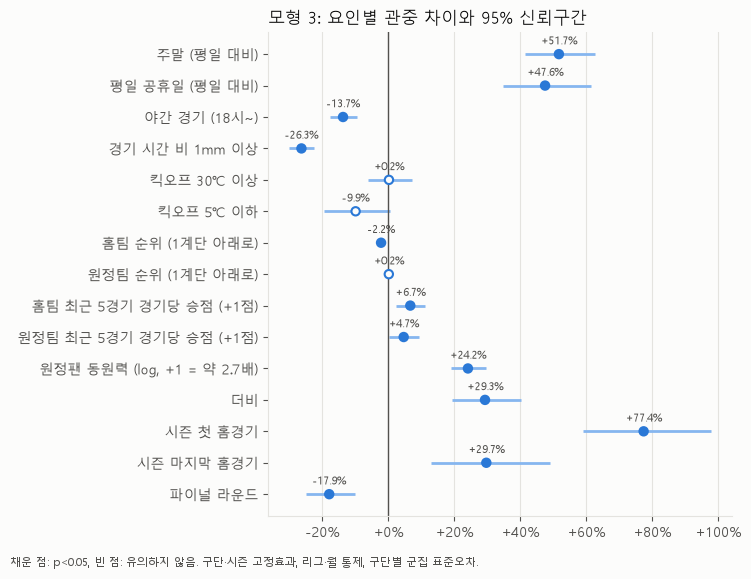

In [5]:
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Malgun Gothic", "axes.unicode_minus": False, "savefig.dpi": 200,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#e4e3df", "axes.grid": True, "grid.color": "#e4e3df",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.labelcolor": "#52514e"})
g = t3.iloc[::-1]
sig = g["p"] < 0.05
fig, ax = plt.subplots(figsize=(7.5, 5.6))
ax.hlines(range(len(g)), g["95% 하한(%)"], g["95% 상한(%)"], color="#86b6ef", linewidth=2)
ax.scatter(g["효과(%)"], range(len(g)), s=36, color=np.where(sig, "#2a78d6", "#fcfcfb"),
           edgecolor="#2a78d6", linewidth=1.5, zorder=3)
for y, (v, p) in enumerate(zip(g["효과(%)"], g["p"])):
    ax.annotate(f"{v:+.1f}%", (v, y), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color="#52514e")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(range(len(g)), g.index)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.grid(axis="y", visible=False)
ax.set_title("모형 3: 요인별 관중 차이와 95% 신뢰구간", loc="left", fontsize=12)
fig.text(0.01, -0.02, "채운 점: p<0.05, 빈 점: 유의하지 않음. 구단·시즌 고정효과, 리그·월 통제, 구단별 군집 표준오차.",
         fontsize=8, color="#52514e")
fig.tight_layout(); fig.savefig(ROOT / "reports" / "figures" / "04_model3_effects.png", bbox_inches="tight"); plt.show()

## 다중공선성 확인 (VIF)

VIF는 한 변수가 다른 설명변수들로 얼마나 설명되는지를 본다. 10을 넘으면 계수가 불안정할 수 있다고 본다. 고정효과·월 더미는 빼고 관심 변수만 계산한다.

In [6]:
vif_cols = ["night", "rain", "hot", "cold", "home_rank_pre", "away_rank_pre", "home_form5", "away_form5",
            "home_first_game", "away_first_game", "ln_away_fans_pre", "away_fans_missing", "derby",
            "home_opener", "last_home", "final_round", "k1"]
X = pd.concat([pd.get_dummies(d["day_type"], drop_first=True, dtype=float), d[vif_cols].astype(float)], axis=1)
X.insert(0, "const", 1.0)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])], index=X.columns[1:], name="VIF")
vif.sort_values(ascending=False).round(2).to_frame()

,VIF
away_first_game,18.70
home_first_game,18.48
ln_away_fans_pre,2.64
home_opener,2.38
away_rank_pre,2.24
away_fans_missing,2.13
home_rank_pre,2.03
away_form5,2.02
home_form5,2.01
k1,1.74


## 민감도 분석 (미리 정한 두 가지만)

1. 매진으로 보이는 경기(`sellout_proxy`=1, 33경기)를 뺀 모형 3
2. 날씨를 대체 관측소 기준(`rain_alt`, `hot_alt`, `cold_alt`)으로 바꾼 모형 3

In [7]:
sens = {
    "모형 3 (본 분석)": models["모형 3"],
    "매진 경기 제외": fit(M3, d[d["sellout_proxy"] == 0]),
    "대체 관측소 날씨": fit(M3.replace("rain", "rain_alt").replace("hot", "hot_alt").replace("cold", "cold_alt"), d),
}
ALT = {"rain_alt": "rain", "hot_alt": "hot", "cold_alt": "cold"}
def table_alt(m):
    t = pd.DataFrame({"b": m.params.rename(ALT), "p": m.pvalues.rename(ALT)})
    t = t.loc[[k for k in LABELS if k in t.index]]
    t.index = [LABELS[k] for k in t.index]
    return t.apply(lambda r: f"{(np.exp(r['b']) - 1) * 100:+.1f}%{stars(r['p'])}", axis=1)
cmp = pd.concat({k: table_alt(m) for k, m in sens.items()}, axis=1)
cmp = cmp.astype(object)
cmp.loc["N"] = [int(m.nobs) for m in sens.values()]
cmp

,모형 3 (본 분석),매진 경기 제외,대체 관측소 날씨
주말 (평일 대비),+51.7%***,+51.8%***,+51.3%***
평일 공휴일 (평일 대비),+47.6%***,+47.2%***,+46.8%***
야간 경기 (18시~),-13.7%***,-13.9%***,-14.1%***
경기 시간 비 1mm 이상,-26.3%***,-26.4%***,-25.5%***
킥오프 30℃ 이상,+0.2%,-0.4%,-0.3%
킥오프 5℃ 이하,-9.9%*,-11.1%**,-8.3%
홈팀 순위 (1계단 아래로),-2.2%***,-2.2%***,-2.1%***
원정팀 순위 (1계단 아래로),+0.2%,+0.2%,+0.1%
홈팀 최근 5경기 경기당 승점 (+1점),+6.7%***,+6.8%***,+6.6%***
원정팀 최근 5경기 경기당 승점 (+1점),+4.7%**,+4.8%**,+4.5%**


## 해석 (모형 3 기준, 모두 '연관성')

같은 구단의 경기끼리 비교했고(구단·시즌 고정효과), 리그와 월을 통제했다. 아래 %는 "다른 조건이 같을 때 관중이 평균 몇 % 달랐나"이다.

**일정**
- 주말 경기는 평일보다 관중이 **약 52%** 많았고, **평일 공휴일도 약 48%** 많아 주말과 거의 비슷했다.
- 주말·공휴일 경기 가운데 **저녁(18시 이후) 경기는 낮 경기보다 약 14% 적었다.** 다만 경기 시간은 연맹이 정하므로 해석에 주의가 필요하다(`docs/limitations.md`).

**날씨 (경기 시간대 기준)**
- 경기 시간 전후에 **비가 1mm 이상 오면 관중이 약 26% 적었다.** 분석한 요인 가운데 통제할 수 없으면서 영향이 가장 큰 요인이다.
- 킥오프 기온 30℃ 이상은 관중과 뚜렷한 관계가 없었다. 5℃ 이하는 약 10% 적었지만 통계적으로 약하다(p≈0.07).

**경기력**
- 홈팀 순위가 1계단 낮을수록 관중이 약 2% 적었고, 홈팀 최근 5경기 경기당 승점이 1점 높을수록 약 7% 많았다.
- 원정팀의 최근 성적도 관중과 관련이 있었다(+1점당 약 5%). 원정팀 순위는 관계가 없었다.

**상대팀·특별 경기**
- 원정 팬 동원력(원정팀이 직전 원정경기들에서 데려온 원정 관중)이 **2배인 상대와 붙으면 관중이 약 16% 많았다.** 결과표·그림의 '원정팬 동원력 (log +1) +24%'와 같은 계수(0.216)를 원정 팬 2배 기준으로 바꾼 값이다 (2^0.216 − 1).
- **더비는 약 29%, 시즌 첫 홈경기는 약 77%, 시즌 마지막 홈경기는 약 30%** 관중이 많았다.
- K리그1 **파이널 라운드(34~38R)는 약 18% 적었다.**

**검증**
- 매진 경기를 빼거나(33경기), 날씨를 대체 관측소 기준으로 바꿔도 계수가 거의 변하지 않았다.
- VIF는 관심 변수 모두 3 미만이다. 시즌 첫 경기 더미 두 개(`home_first_game`, `away_first_game`)만 18 정도인데, 1라운드에는 두 팀이 같이 첫 경기를 치르기 때문이다. 이 두 변수는 빈칸을 처리하려고 넣은 것이라 해석하지 않으므로 문제가 되지 않는다.

## 구단 마케팅 담당자가 할 수 있는 일 (예시)

> **예시입니다.** 아래 제안은 분석 결과에서 떠올린 아이디어로, 실제 효과가 확인된 것은 아닙니다. 실제 제안은 다른 리그·구단의 성공 사례를 근거로 다시 작성할 예정이며, 사례는 `docs/benchmark_cases.md`에 모으고 있습니다.

| 결과 | 할 수 있는 일 (예시) |
| --- | --- |
| 평일 공휴일 관중이 주말과 비슷 | 일정 협의 때 평일 공휴일 홈경기 배정을 요청하고, 공휴일 가족 단위 프로모션에 집중 |
| 경기 시간 비 −26% | 강수 예보 기반 관중 예측으로 인력·매점 재고 조정, 우천 시 우비 제공·예매 취소 정책으로 이탈 줄이기 |
| 시즌 첫·마지막 홈경기, 더비 +30~77% | 이미 관중이 몰리는 경기는 객단가(굿즈·F&B) 극대화, 신규 팬 전환(다음 경기 할인권) 기회로 활용 |
| 원정 팬 동원력이 높은 상대와의 경기 관중 증가 | 인기 원정팀 경기에 원정석 확대·원정 팬 패키지 판매 |
| 파이널 라운드 −18% | 순위 경쟁이 끝난 경기에 대비한 별도 이벤트(시즌권 갱신 행사 등) 기획 |
| 홈팀 성적과 관중 연관 | 성적은 마케팅이 통제할 수 없으므로, 성적이 나쁠 때도 유지되는 경기장 경험(이벤트·먹거리)에 투자 |
